In [1]:
import csv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
def get_df(filename):
    df = pd.read_csv(
        filename,
        header=0,
        names=["threads/func", "func1", "func2", "func3"]
    )

    df = df.rename(columns={"threads/func": "threads"})

    return df

In [3]:
df_atomic = get_df("./data/measurements_atomic_bad.csv")
df_atomic

,threads,func1,func2,func3
0,1,19910.666667,1041.666667,3156.000000
1,2,10994.333333,1357.666667,1979.333333
2,4,6163.666667,1429.000000,1684.666667
3,8,4379.333333,1548.333333,1641.333333
4,16,2949.666667,1604.666667,1670.333333
5,20,2745.666667,1762.333333,1748.000000
6,100,2639.000000,1831.000000,1816.333333
7,1000,4343.333333,1892.666667,2067.333333


In [4]:
df_mutex = get_df("./data/measurements_mutex_bad.csv")
df_mutex

,threads,func1,func2,func3
0,1,19897.666667,1041.000000,3266.666667
1,2,45303.000000,5765.333333,7302.333333
2,4,47753.666667,5185.333333,9669.333333
3,8,64714.333333,6651.000000,13657.333333
4,16,82508.333333,13127.666667,23323.000000
5,20,94225.000000,15100.333333,29391.000000
6,100,85173.333333,7092.333333,15133.666667
7,1000,78828.333333,7025.333333,14453.000000


In [5]:
percentage_diff = pd.DataFrame()
percentage_diff["threads"] = df_atomic["threads"]
for func in ["func1", "func2", "func3"]:
    percentage_diff[f"{func}_%_diff"] = (
        (df_mutex[func] - df_atomic[func]) / df_atomic[func]
    ) * 100

percentage_diff

,threads,func1_%_diff,func2_%_diff,func3_%_diff
0,1,-0.065292,-0.064000,3.506548
1,2,312.057727,324.650135,268.928932
2,4,674.760694,262.864474,473.961219
3,8,1377.721114,329.558665,732.087734
4,16,2697.208724,718.093062,1296.308122
5,20,3331.771276,756.837526,1581.407323
6,100,3127.485159,287.347533,733.198752
7,1000,1714.927091,271.187038,599.113189


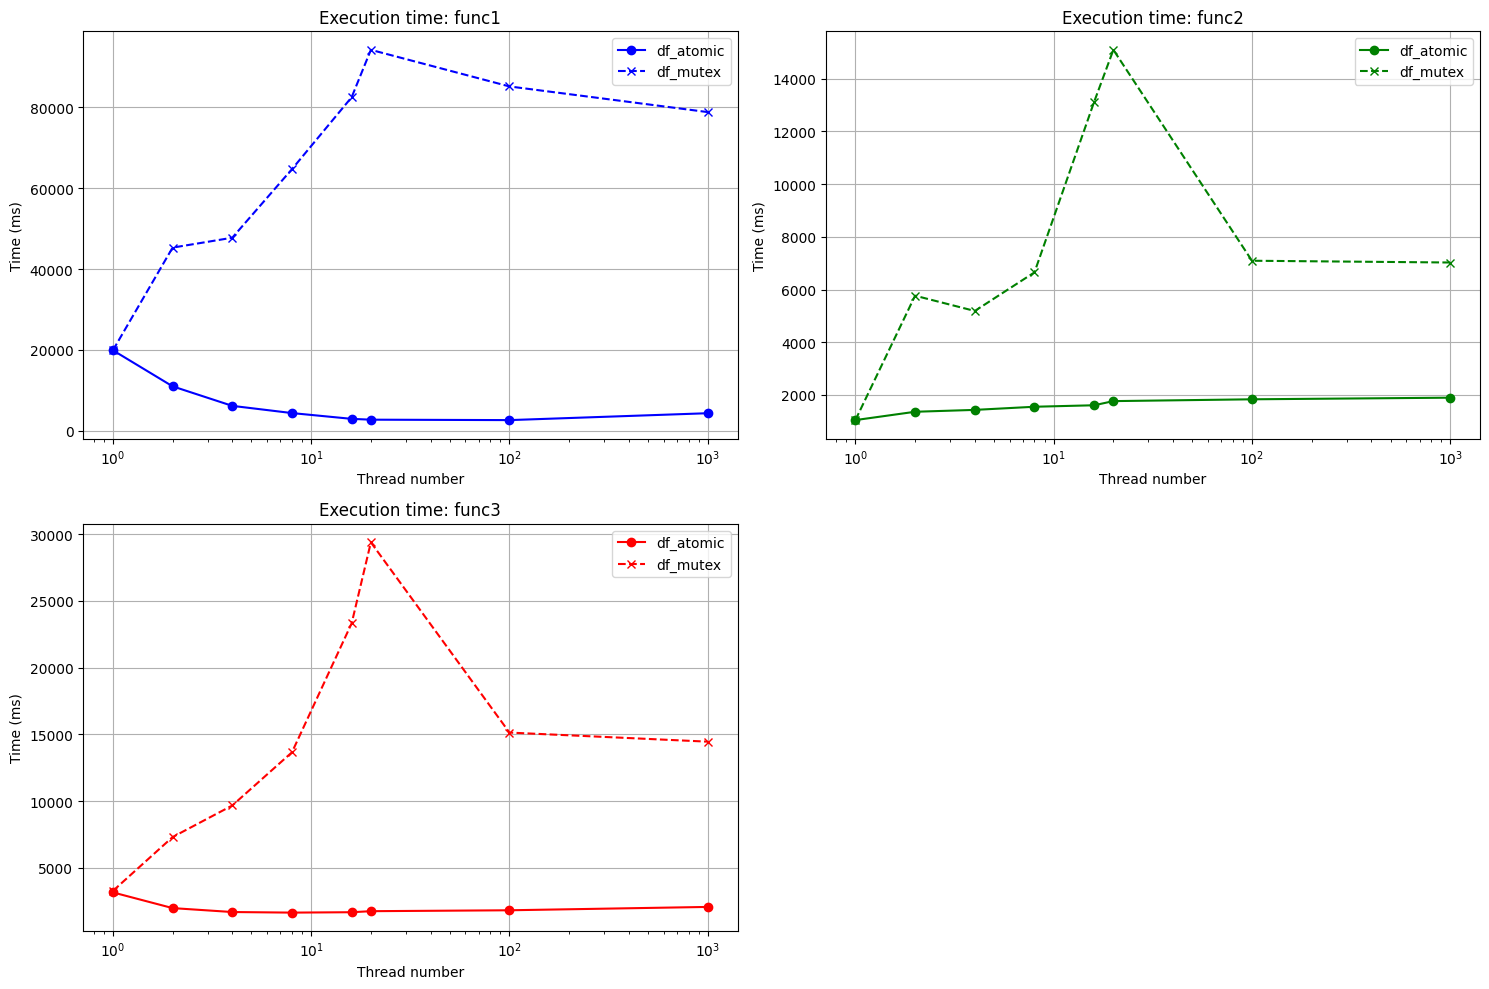

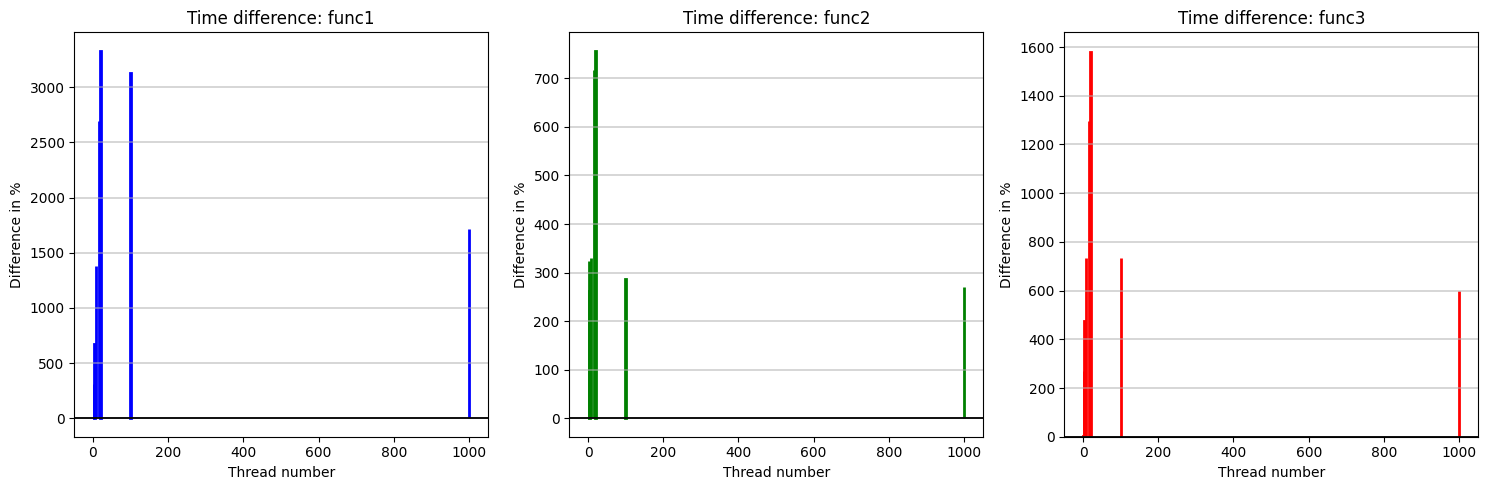

In [6]:
functions = ["func1", "func2", "func3"]
colors = ["blue", "green", "red"]

plt.figure(figsize=(15, 10))
for i, func in enumerate(functions):
    plt.subplot(2, 2, i + 1)
    plt.plot(
        df_atomic["threads"],
        df_atomic[func],
        marker="o",
        label="df_atomic",
        color=colors[i],
    )
    plt.plot(
        df_mutex["threads"],
        df_mutex[func],
        marker="x",
        label="df_mutex",
        linestyle="--",
        color=colors[i],
    )

    plt.xlabel("Thread number")
    plt.ylabel("Time (ms)")
    plt.title(f"Execution time: {func}")
    plt.xscale("log")
    plt.grid(True)
    plt.legend()

plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 5))
for i, func in enumerate(functions):
    plt.subplot(1, 3, i + 1)

    plt.bar(
        percentage_diff["threads"],
        percentage_diff[f"{func}_%_diff"],
        color=colors[i],
        edgecolor=colors[i],
        linewidth=2,
    )
    plt.xlabel("Thread number")
    plt.ylabel("Difference in %")
    plt.title(f"Time difference: {func}")
    plt.axhline(0, color="black", linewidth=1.3)
    plt.grid(axis="y", linewidth=1.2, alpha=0.6)

plt.tight_layout()
plt.show()

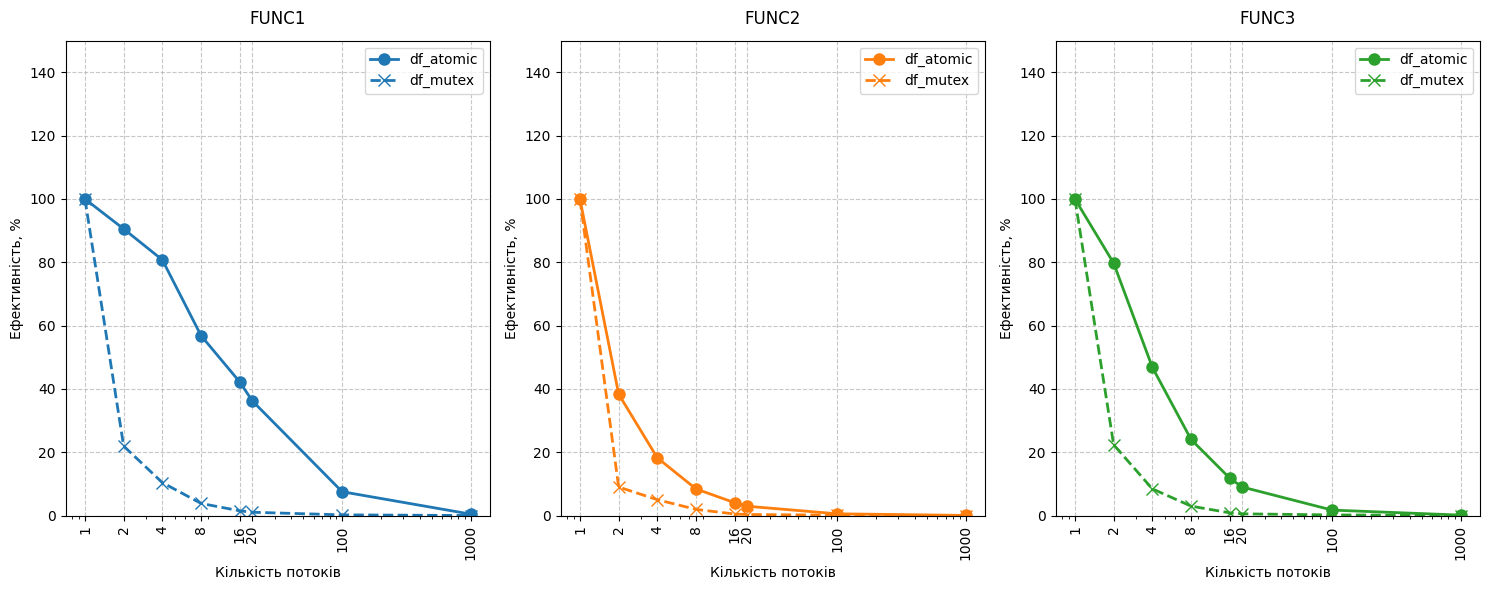

In [7]:
def calculate_efficiency(df):
    efficiency = pd.DataFrame()
    efficiency["threads"] = df["threads"]
    for func in ["func1", "func2", "func3"]:
        t1 = df[df["threads"] == 1][func].values[0]
        efficiency[f"{func}_eff"] = (t1 / df[func]) / df["threads"] * 100
    return efficiency


eff1 = calculate_efficiency(df_atomic)
eff2 = calculate_efficiency(df_mutex)


plt.figure(figsize=(15, 6))
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
line_styles = ["-", "--"]
labels = ["df_atomic", "df_mutex"]

for i, func in enumerate(["func1", "func2", "func3"]):
    plt.subplot(1, 3, i + 1)

    plt.plot(
        eff1["threads"],
        eff1[f"{func}_eff"],
        marker="o",
        linestyle=line_styles[0],
        linewidth=2,
        color=colors[i],
        markersize=8,
        label=labels[0],
    )

    plt.plot(
        eff2["threads"],
        eff2[f"{func}_eff"],
        marker="x",
        linestyle=line_styles[1],
        linewidth=2,
        color=colors[i],
        markersize=8,
        label=labels[1],
    )

    plt.xscale("log")
    plt.xticks(eff1["threads"], labels=eff1["threads"], rotation=90)
    plt.xlabel("Кількість потоків", fontsize=10)
    plt.ylabel("Ефективність, %", fontsize=10)
    plt.title(f"{func.upper()}", fontsize=12, pad=12)
    plt.grid(True, linestyle="--", alpha=0.7)
    plt.ylim(0, 150)
    plt.legend()

plt.tight_layout()
plt.show()